## **An Intuitive Physics Approach to Modeling Melodic Expectation**

### **Generative Model**

In [1]:
import Pkg
Pkg.activate("MusicalExpectation")
Pkg.add("Gen")
Pkg.add("Plots")
Pkg.add(["CSV", "DataFrames"])
Pkg.add("Distributions")
Pkg.add("HypothesisTests")
Pkg.add("GLM")
Pkg.add("ProgressBars")
Pkg.add("JSON")

include("utils/draw.jl")
include("utils/scale.jl")
include("utils/force.jl")
include("utils/data.jl")

using Gen
using Plots
using CSV
using ProgressBars
using DataFrames
using Distributions
using Statistics
using HypothesisTests
using Random
using GLM
using JSON
using .ScaleUtils
using .ForceUtils
using .DataUtils
;

  Activating project at `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation`
   Resolving package versions...
     Project No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Project.toml`
    Manifest No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Project.toml`
    Manifest No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Project.toml`
    Manifest No packages added to or removed from `~/Desktop/Music/MusicRepository_0826_v2/Code/MusicalExpectation/Manifest.toml`
   Resolving package versions...
 

In [2]:
# Creates some major scales to draw from later on
C = create_major_scale(60)

G = create_major_scale(55)  
D = create_major_scale(62)  
A = create_major_scale(57)  
E = create_major_scale(64)  
B = create_major_scale(59)  
F♯ = create_major_scale(66)
C♯ = create_major_scale(61)


F = create_major_scale(65)
B♭ = create_major_scale(58)
E♭ = create_major_scale(63)
A♭ = create_major_scale(56)
D♭ = create_major_scale(61)
G♭ = create_major_scale(66)
C♭ = create_major_scale(59)



major_scales = [C, G, D, A, E, B, F♯, C♯, F, B♭, E♭, A♭, D♭, G♭, C♭]
;

In [3]:
# Initialize params
σ_gravity = 0.2
σ_magnetism = 1.5
σ_inertia = 0.01
σ_note = 0.025
w_g, w_m, w_i = 1.2, 0.1, 4.0
α = 0.1
σ_step_base  = 0.6
σ_pitch_obs  = 0.7
γ = 0.25
;

In [4]:
"""
Single step transition in the melody model. Samples duration Δt and next note based on gravity, magnetism, and inertia forces.
"""
@gen function melody_kernel(k::Int, state::Tuple{Note,Note}, key::MusicalScale, measure_length::Int=8)
    # Initial scaling parameters
    prev_note, curr_note = state

    # Rhythmic transition
    Δt ~ categorical(fill(1.0 / measure_length, measure_length))

    # Force calculations
    gravity   = @trace(normal(calculate_gravity(curr_note, key), σ_gravity), :gravity)
    magnetism = @trace(normal(calculate_magnetism(curr_note, key), σ_magnetism), :magnetism)
    inertia   = @trace(normal(calculate_inertia(prev_note, curr_note, key), σ_inertia), :inertia)

    base_force   = w_g*gravity + w_m*magnetism + w_i*inertia
    
    # rhythm_scale = 1 / sqrt(max(Δt, 1))
    rhythm_scale = (Δt)^γ

    μ_step = α * rhythm_scale * base_force
    σ_step = σ_step_base * sqrt(Δt)

    step ~ normal(μ_step, σ_step)

    # Soft pitch anchoring
    next_pitch = curr_note.value + step
    next_pos   = mod(curr_note.position - 1 + Δt, measure_length) + 1
    obs_pitch ~ normal(next_pitch, σ_pitch_obs)

    next_note = Note(next_pitch, next_pos)
    return (curr_note, next_note)
end
;

In [5]:
chain = Gen.Unfold(melody_kernel)

"""
Generate a melody of K notes. Optionally specify the key and initial notes.
"""

@gen function melody(
    K::Int,
    key=nothing,
    init_notes=nothing
)
    σ_init = 0.05

    # Second order initialization
    key = isnothing(key) ?
        @trace(draw(major_scales, fill(1 / length(major_scales), length(major_scales))), :key) :
        key

    if isnothing(init_notes)
        start_pitch ~ normal(key.notes[1].value, σ_init)
        x₁ = Note(start_pitch, 1)

        init_step ~ normal(0, 1)
        x₂ = Note(x₁.value + init_step, 2)

        init_state = (x₁, x₂)
    else
        init_state = init_notes
    end

    states ~ chain(K - 2, init_state, key)

    notes = Note[init_state[1], init_state[2]]
    for st in states
        push!(notes, st[2])
    end

    return notes
end
;

In [6]:
# Example trace
trace = Gen.simulate(melody, (10,)) 
get_retval(trace)

10-element Vector{Note}:
 Note(60.98137020565591, 1)
 Note(60.984258033610296, 2)
 Note(60.17749373421003, 5)
 Note(60.98824606326655, 8)
 Note(58.56520528758667, 5)
 Note(57.86047001804683, 6)
 Note(58.28951112125056, 7)
 Note(60.11958351105491, 4)
 Note(60.891500913899904, 2)
 Note(61.2814403882014, 3)

In [7]:
get_choices(trace)

│
├── :key : MusicalScale(:major, Note[Note(61.0, 1), Note(63.0, 1), Note(65.0, 1), Note(66.0, 1), Note(68.0, 1), Note(70.0, 1), Note(72.0, 1), Note(73.0, 1)], 61)
│
├── :start_pitch : 60.98137020565591
│
├── :init_step : 0.0028878279543896913
│
└── :states
    │
    ├── 1
    │   │
    │   ├── :step : -0.8067642994002628
    │   │
    │   ├── :magnetism : 0.03308525993151104
    │   │
    │   ├── :obs_pitch : 60.75977264129284
    │   │
    │   ├── :gravity : -0.15608163319267943
    │   │
    │   ├── :Δt : 3
    │   │
    │   └── :inertia : 0.25061172680201327
    │
    ├── 2
    │   │
    │   ├── :step : 0.8107523290565197
    │   │
    │   ├── :magnetism : -1.4977881786501883
    │   │
    │   ├── :obs_pitch : 60.958242898365064
    │   │
    │   ├── :gravity : -0.06474081090583907
    │   │
    │   ├── :Δt : 3
    │   │
    │   └── :inertia : -0.24319468064277927
    │
    ├── 3
    │   │
    │   ├── :step : -2.423040775679881
    │   │
    │   ├── :magnetism : -0.0146062586466609

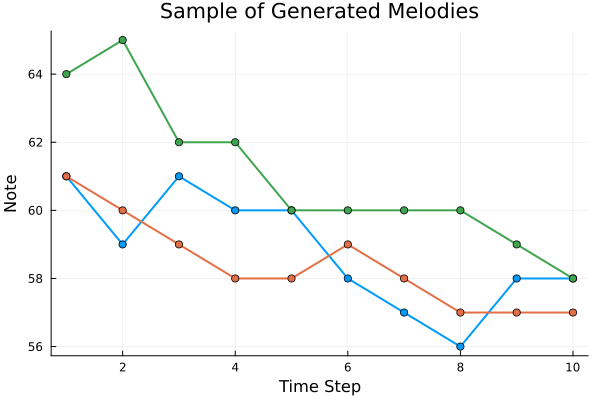

In [8]:
# Visualize a sample of traces
num_traces = 3
traces = Vector{Gen.DynamicDSLTrace}(undef, num_traces)
vecs = Vector{Vector{Float64}}(undef, num_traces)
choices = []

for i in 1:num_traces
    trace = Gen.simulate(melody, (10,))
    melody_notes = get_retval(trace)
    pitches = [round(n.value) for n in melody_notes]
    push!(choices, get_choices(trace))

    traces[i] = trace
    vecs[i] = pitches
end

plot(vecs, line=:solid, legend=false, marker = :circle, linewidth=2)
xlabel!("Time Step")
ylabel!("Note")
title!("Sample of Generated Melodies")

In [9]:
"""
Convert a pitch sequence into line segments for plotting, grouping consecutive
equal pitches.
"""

function step_segments(pitches)
    p = round.(Int, pitches)
    T = length(p)
    xs = Float64[]
    ys = Float64[]
    t = 1
    while t <= T
        y = p[t]
        t2 = t
        while t2 < T && p[t2+1] == y
            t2 += 1
        end
        append!(xs, [t, t2 + 1, NaN])
        append!(ys, [y, y, NaN])
        t = t2 + 1
    end
    return xs, ys
end

"""
Add piano-roll style rectangles to a plot for the given pitch sequence.
"""
function add_roll!(plt, pitches, color; height=0.8)
    p = round.(Int, pitches)
    T = length(p)
    t = 1
    while t <= T
        y = p[t]
        t2 = t
        while t2 < T && p[t2+1] == y
            t2 += 1
        end

        x1 = t
        x2 = t2 + 1
        y1 = y - height/2
        y2 = y + height/2

        shape = Shape([x1, x2, x2, x1],
                      [y1, y1, y2, y2])

        plot!(plt, shape;
            color = color,
            linecolor = :transparent
        )

        t = t2 + 1
    end
end
;

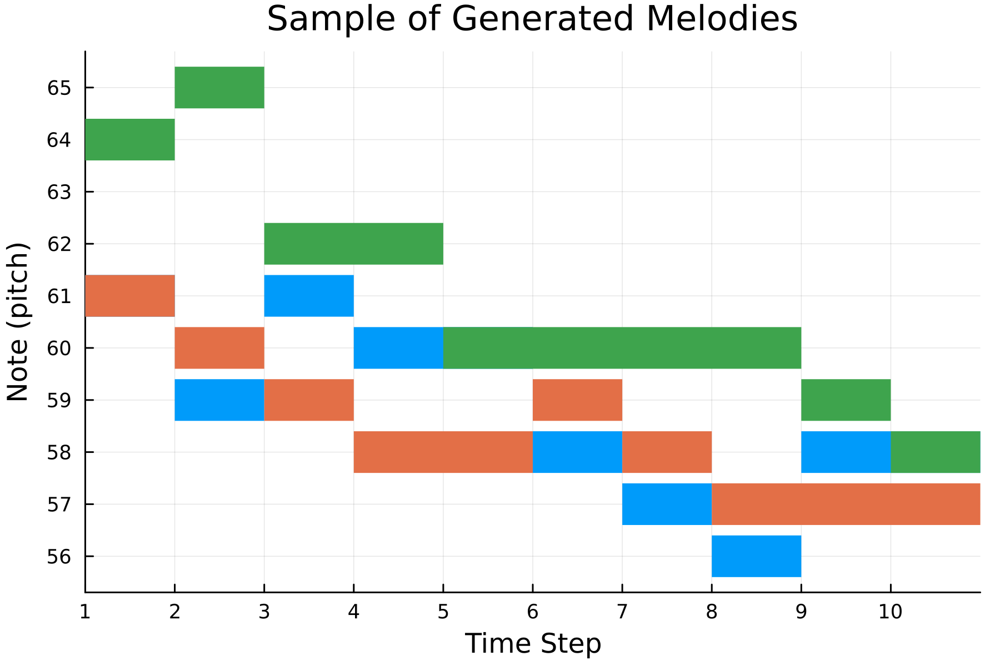

In [10]:
# Visualize piano roll of generated melodies
all_pitches = round.(Int, vcat(vecs...))

plt = plot(
    legend=false,
    xticks = 1:10,
    xlims = (1, 11),
    yticks = minimum(all_pitches):maximum(all_pitches),
    dpi = 300
)

colors = palette(:default)

for (i, pitches) in enumerate(vecs)
    add_roll!(plt, pitches, colors[i])
end

xlabel!(plt, "Time Step")
ylabel!(plt, "Note (pitch)")
title!(plt, "Sample of Generated Melodies")
display(plt)

savefig(plt, "exports/melody_plot1.png")
;

### **Inference by particle filtering**

In [11]:
MEASURE_LENGTH = 8

"""
Run particle filter on observed melody data. Returns sampled traces.
"""

function particle_filter(num_particles::Int, num_samples::Int,
                         key::MusicalScale, obs_df::DataFrame,
                         model=melody)

    T = nrow(obs_df)
    @assert T ≥ 2 "Need at least two observed notes"

    obs_notes  = Vector{Note}(obs_df.obs_notes)
    init_state = (obs_notes[1], obs_notes[2])

    # Key is an input argument, not a traced random choice
    init_obs  = Gen.choicemap()
    init_args = (2, key, init_state)

    state = Gen.initialize_particle_filter(model, init_args, init_obs, num_particles)

    for t in 3:T
        Gen.maybe_resample!(state, ess_threshold = num_particles ÷ 4)

        K = t
        k = t - 2

        Δt = mod(obs_df[t, :position] - obs_df[t-1, :position], MEASURE_LENGTH)
        Δt = (Δt == 0) ? MEASURE_LENGTH : Δt

        obs = Gen.choicemap()
        obs[:states => k => :Δt]        = Δt
        obs[:states => k => :obs_pitch] = obs_notes[t].value

        new_args = (K, key, init_state)
        Gen.particle_filter_step!(
            state,
            new_args,
            (UnknownChange(), NoChange(), NoChange()),
            obs
        )
    end

    # Final forecast step
    K_forecast = T + 1
    k_forecast = K_forecast - 2

    last_pos = obs_df[T, :position]
    Δt_f = mod(1 - last_pos, MEASURE_LENGTH)
    Δt_f = (Δt_f == 0) ? MEASURE_LENGTH : Δt_f

    obs_f = Gen.choicemap()
    obs_f[:states => k_forecast => :Δt] = Δt_f

    Gen.particle_filter_step!(
        state,
        (K_forecast, key, init_state),
        (UnknownChange(), NoChange(), NoChange()),
        obs_f
    )

    return Gen.sample_unweighted_traces(state, num_samples)
end
;

In [12]:
_lse(xs) = (m = maximum(xs); m + log(sum(exp, xs .- m)))

"""
Calculate log-likelihood of a melody under the model.
Returns (stem_ll, pred_note_ll).
"""

function melody_log_likelihood(
    observed_notes::Vector{Float64},
    observed_rhythms::Vector{Float64},
    observed_key::MusicalScale,
    target_note::Float64;
    n_particles::Int = 1000,
    n_samples::Int   = 500,
    model            = melody
)
    obs_df     = make_observations(observed_notes, observed_rhythms, observed_key)
    T          = nrow(obs_df)
    obs_notes  = Vector{Note}(obs_df.obs_notes)
    init_state = (obs_notes[1], obs_notes[2])

    # Particle filter over stem notes
    init_obs = Gen.choicemap()
    state = Gen.initialize_particle_filter(model, (2, observed_key, init_state),
                                            init_obs, n_particles)

    for t in 3:T
        Gen.maybe_resample!(state, ess_threshold = n_particles ÷ 4)
        k  = t - 2
        Δt = mod(obs_df[t, :position] - obs_df[t-1, :position], MEASURE_LENGTH)
        Δt = (Δt == 0) ? MEASURE_LENGTH : Δt

        obs = Gen.choicemap()
        obs[:states => k => :Δt]        = Δt
        obs[:states => k => :obs_pitch] = obs_notes[t].value

        Gen.particle_filter_step!(state, (t, observed_key, init_state),
                                   (UnknownChange(), NoChange(), NoChange()), obs)
    end

    # Stem log-likelihood: accumulated particle filter ML estimate over stem
    stem_ll = state.log_ml_est

    # Forecast step (condition on Δt only, sample next pitch)
    last_pos = obs_df[T, :position]
    Δt_f     = mod(1 - last_pos, MEASURE_LENGTH)
    Δt_f     = (Δt_f == 0) ? MEASURE_LENGTH : Δt_f
    k_f      = T - 1  # = (T+1) - 2

    obs_f = Gen.choicemap()
    obs_f[:states => k_f => :Δt] = Δt_f
    Gen.particle_filter_step!(state, (T + 1, observed_key, init_state),
                               (UnknownChange(), NoChange(), NoChange()), obs_f)

    pf_traces    = Gen.sample_unweighted_traces(state, n_samples)
    pred_pitches = Float64[tr[:states][end][2].value for tr in pf_traces]

    # log p(target_note | stem) ≈ log (1/N Σ_i p(target_note | particle_i))
    pred_note_ll = _lse([Distributions.logpdf(Normal(p, σ_pitch_obs), target_note)
                         for p in pred_pitches]) - log(n_samples)

    return stem_ll, pred_note_ll
end
;

In [13]:
# Particle filter test case
key = G

# Observed notes and their rhythmic positions. Let's say we have a 4/4 measure.
# Actual last note is 67.
observed_note_values = [62.0, 59.0, 55.0, 62.0, 64.0, 60.0, 66.0, 62.0, 67.27]

observed_positions = [1.0, 3.0, 5.0, 7.0, 5.0, 6.0, 7.0, 8.0, 1.0]

observed_notes = make_observations(observed_note_values[1:end-1], observed_positions[1:end-1], key)
observed_notes

Row,obs_notes,position,gravity,magnetism,inertia
,Note,Float64,Float64,Float64,Float64
1,"Note(62.0, 1)",1.0,-2.0,-0.0,0.0
2,"Note(59.0, 3)",3.0,-2.0,0.5,-0.1875
3,"Note(55.0, 5)",5.0,0.0,0.16,-0.1625
4,"Note(62.0, 7)",7.0,-2.0,-0.0,0.2125
5,"Note(64.0, 5)",5.0,-2.0,5.55112e-13,0.225
6,"Note(60.0, 6)",6.0,-1.0,-0.5,-0.2
7,"Note(66.0, 7)",7.0,-2.0,0.5,0.2375
8,"Note(62.0, 8)",8.0,-2.0,-0.0,-0.2125


In [14]:
pf_traces = particle_filter(100, 100, key, observed_notes)
;

In [15]:
last_notes = Note[]

for trace in pf_traces
    states = trace[:states]
    (_, last_note) = states[end] # curr_note at final step
    push!(last_notes, last_note)
end

pred_note_vals = [n.value for n in last_notes]
mu = mean(pred_note_vals)

62.28769617219812

In [16]:
"""
Plot sampled melody continuations along with observed notes.
"""

function visualize_samples(samples::Vector{Gen.DynamicDSLTrace},
                           obs_notes::Vector{Note},
                           melody_name::String)

    plot()
    pred_note_vals = Float64[]

    for trace in samples
        states = trace[:states]  # Vector{Tuple{Note, Note}}

        # Reconstruct melody: take curr_note from each state
        notes = [obs_notes[1] ; obs_notes[2] ; [st[2] for st in states]]

        seq_vals = [n.value for n in notes]
        push!(pred_note_vals, seq_vals[end])

        plot!(
            seq_vals,
            linewidth = 2,
            alpha = 0.20,
            color = :steelblue,
            legend = false
        )
    end

    # Observed melody
    obs_vals = [n.value for n in obs_notes]
    plot!(
        obs_vals,
        linewidth = 4,
        linestyle = :solid,
        color = :navy,
        label = "Observed Sequence"
    )

    true_final = obs_vals[end]
    mu = mean(pred_note_vals)

    hline!(
        [true_final],
        color = :black,
        linewidth = 1,
        linestyle = :solid,
        label = "True Final Note"
    )

    hline!(
        [mu],
        color = :black,
        linewidth = 1,
        linestyle = :dash,
        label = "Mean Predicted Final Note"
    )

    xlabel!("Time Step")
    ylabel!("Pitch (MIDI)")
    title!("Particle Filter Samples - $melody_name")
    display(plot!())
    plot!(
        xtickfontsize = 16,
        ytickfontsize = 16
    )
    return plot!()
end
;

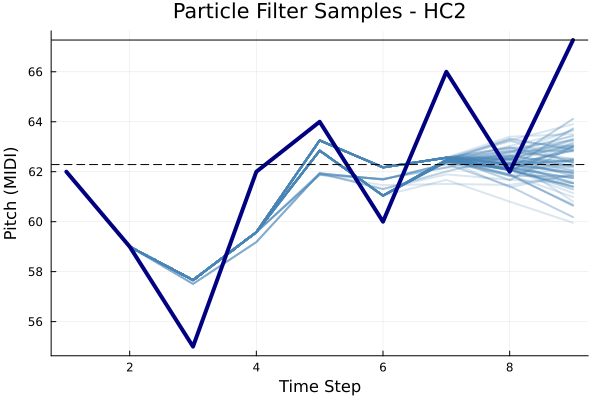

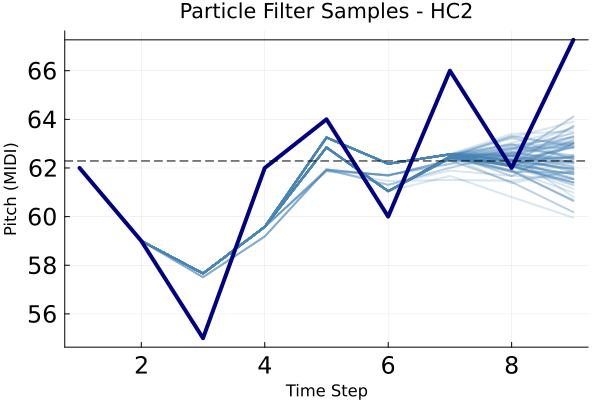

In [17]:
# Particle filter visualization test case
observed_notes = [Note(n, p) for (n, p) in zip(observed_note_values, observed_positions)]

visualize_samples(pf_traces, observed_notes, "HC2")

### **Model vs Human Performance**

In [18]:
# Initializing a load_keys function
const KEY_MAP = Dict(
    "C"  => C,
    "G"  => G,
    "D"  => D,
    "A"  => A,
    "E"  => E,
    "B"  => B,
    "F#" => F♯,
    "Gb" => G♭,
    "Db" => D♭,
    "Ab" => A♭,
    "Eb" => E♭,
    "Bb" => B♭,
    "F"  => F
)

"""
Load musical keys from CSV file using KEY_MAP.
"""
function load_keys(path::String)
    df = DataFrame(CSV.File(path, missingstring="NA"))

    return [
        KEY_MAP[strip(String(row.key))]
        for row in eachrow(df)
    ]
end
;

In [19]:
# Initial data collation
stemIDs, melodies, human_means = load_melodies("./data/all_melodies_final_means.csv")
melody_keys = load_keys("./data/all_keys.csv")
rhythms, rhythm_labels = load_rhythms("./data/all_rhythms.csv")
lengths = load_measures("./data/all_times.csv")

for i in 1:length(melodies) 
    println("Melody $i") 
    println(" Stem ID: ", stemIDs[i]) 
    println(" Key: ", melody_keys[i]) 
    println(" Notes: ", melodies[i]) 
    println(" Rhythms: ", rhythms[i]) 
    println(" Human Mean: ", human_means[i]) 
    println() 
end

Melody 1
 Stem ID: AC1
 Key: MusicalScale(:major, Note[Note(55.0, 1), Note(57.0, 1), Note(59.0, 1), Note(60.0, 1), Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1)], 55)
 Notes: [62.0, 59.0, 55.0, 62.0, 64.0, 60.0, 66.0, 62.0]
 Rhythms: [1.0, 3.0, 5.0, 8.0, 1.0, 3.0, 5.0, 8.0]
 Human Mean: 66.8

Melody 2
 Stem ID: NC1
 Key: MusicalScale(:major, Note[Note(55.0, 1), Note(57.0, 1), Note(59.0, 1), Note(60.0, 1), Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1)], 55)
 Notes: [64.0, 60.0, 57.0, 64.0, 66.0, 62.0, 67.0, 64.0]
 Rhythms: [1.0, 3.0, 5.0, 8.0, 1.0, 3.0, 5.0, 8.0]
 Human Mean: 64.76923077

Melody 3
 Stem ID: AC2
 Key: MusicalScale(:major, Note[Note(62.0, 1), Note(64.0, 1), Note(66.0, 1), Note(67.0, 1), Note(69.0, 1), Note(71.0, 1), Note(73.0, 1), Note(74.0, 1)], 62)
 Notes: [62.0, 69.0, 66.0, 64.0, 57.0, 61.0]
 Rhythms: [1.0, 5.0, 7.0, 1.0, 5.0, 7.0]
 Human Mean: 61.88461538

Melody 4
 Stem ID: NC2
 Key: MusicalScale(:major, Note[Note(62.0, 1), Note(64.0, 1), No

In [20]:
"""
Calculate model predictions for a set of melodies. Returns means, standard deviations, and highest-likelihood predictions.
"""

function calculate_model_means(
    melodies::Vector{Vector{Float64}},
    rhythms::Vector{Vector{Float64}},
    melody_keys::Vector{MusicalScale},
    n_particles::Int = 1000,
    horizon::Int = 100
)
    num_melodies = length(melodies)

    @assert length(rhythms) == num_melodies
    @assert length(melody_keys) == num_melodies

    mean_last_notes_all = Float64[]
    mean_rounded_last_notes_all = Float64[]
    highest_likelihood_notes_all = Float64[]
    sd_last_notes_all = Float64[]
    all_particles_all = Vector{Vector{Float64}}()

    for idx in ProgressBar(1:num_melodies)
        observed_notes   = melodies[idx]
        observed_rhythms = rhythms[idx]
        observed_key     = melody_keys[idx]

        @assert length(observed_notes) == length(observed_rhythms) """
        Melody / rhythm length mismatch at index $idx
        """

        # Build observations + run particle filter
        obs_notes = make_observations(observed_notes, observed_rhythms, observed_key)
        pf_traces = particle_filter(n_particles, horizon, observed_key, obs_notes)

        # Mean over particles
        last_notes = Float64[]
        for tr in pf_traces
            (_, last_note) = tr[:states][end]
            push!(last_notes, last_note.value)
        end

        mean_last_note         = mean(last_notes)
        mean_rounded_last_note = mean(round.(Int, last_notes))
        sd_last_note           = std(last_notes)  # NEW: calculate SD

        # Highest-likelihood particle
        scores  = Gen.get_score.(pf_traces)
        best_i = argmax(scores)

        (_, best_last_note_obj) = pf_traces[best_i][:states][end]
        best_last_note = best_last_note_obj.value

        push!(mean_last_notes_all, mean_last_note)
        push!(mean_rounded_last_notes_all, mean_rounded_last_note)
        push!(highest_likelihood_notes_all, best_last_note)
        push!(sd_last_notes_all, sd_last_note)
        push!(all_particles_all, last_notes)
    end

    return mean_last_notes_all,
           mean_rounded_last_notes_all,
           highest_likelihood_notes_all,
           sd_last_notes_all,
           all_particles_all
end
;

In [21]:
n_runs = 10
cor1_vals = Float64[]
cor2_vals = Float64[]
cor3_vals = Float64[]
cor4_vals = Float64[]

melodies = [Float64.(v) for v in melodies]

for run in 1:n_runs
    model_means, rounded_model_means, max_likelihood_notes, sds, all_particles = calculate_model_means(melodies, rhythms, melody_keys)
    
    rounded_max_likelihood_notes = round.(Int, max_likelihood_notes)

    push!(cor1_vals, cor(human_means, model_means))
    push!(cor2_vals, cor(human_means, rounded_model_means))
    push!(cor3_vals, cor(human_means, max_likelihood_notes))
    push!(cor4_vals, cor(human_means, rounded_max_likelihood_notes))
end

println("Average correlation (model_means): ", mean(cor1_vals))
println("Average correlation (rounded_model_means): ", mean(cor2_vals))
println("Average correlation (max_likelihood_notes): ", mean(cor3_vals))
println("Average correlation (rounded max_likelihood_notes): ", mean(cor4_vals))

0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:00<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:01<01:04, 1it/s]
3.3%┣█▋                                              ┫ 3/90 [00:01<00:39, 2it/s]
4.4%┣██▏                                             ┫ 4/90 [00:01<00:31, 3it/s]
5.6%┣██▊                                             ┫ 5/90 [00:02<00:33, 3it/s]
6.7%┣███▏                                            ┫ 6/90 [00:02<00:29, 3it/s]
7.8%┣███▊                                            ┫ 7/90 [00:02<00:28, 3it/s]
8.9%┣████▎                                           ┫ 8/90 [00:02<00:27, 3it/s]
10.0%┣████▊                                          ┫ 9/90 [00:03<00:27, 3it/s]
11.1%┣█████                                         ┫ 10/90 [00:03<00:27, 3it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:03<00:27, 3it/s]
13.3%┣██████▏               

Average correlation (model_means): 0.744582744278695
Average correlation (rounded_model_means): 0.744475110808332
Average correlation (max_likelihood_notes): 0.7150267475825985
Average correlation (rounded max_likelihood_notes): 0.7123988858915373


100.0%┣█████████████████████████████████████████████┫ 90/90 [00:31<00:00, 3it/s]
100.0%┣█████████████████████████████████████████████┫ 90/90 [00:31<00:00, 3it/s]


In [22]:
# Full model run

melodies = [Float64.(v) for v in melodies]
model_means, rounded_model_means, max_likelihood_notes, sds, all_particles = calculate_model_means(melodies, rhythms, melody_keys)
rounded_max_likelihood_notes = round.(Int, max_likelihood_notes)
print(cor(human_means, model_means), "\n")
print(cor(human_means, rounded_model_means), "\n")
print(cor(human_means, max_likelihood_notes), "\n")
print(cor(human_means, rounded_max_likelihood_notes))
print("\n", "Mean SD: ", mean(sds), "\n")
print("SD range: [", minimum(sds), ", ", maximum(sds), "]\n")

0.0%┣                                               ┫ 0/90 [00:00<00:00, -0s/it]
1.1%┣▌                                          ┫ 1/90 [00:00<Inf:Inf, InfGs/it]
2.2%┣█                                               ┫ 2/90 [00:01<00:54, 2it/s]
3.3%┣█▋                                              ┫ 3/90 [00:01<00:33, 3it/s]
4.4%┣██▏                                             ┫ 4/90 [00:01<00:27, 3it/s]
5.6%┣██▊                                             ┫ 5/90 [00:01<00:25, 3it/s]
6.7%┣███▏                                            ┫ 6/90 [00:01<00:24, 4it/s]
7.8%┣███▊                                            ┫ 7/90 [00:02<00:24, 4it/s]
8.9%┣████▎                                           ┫ 8/90 [00:02<00:23, 3it/s]
10.0%┣████▊                                          ┫ 9/90 [00:02<00:24, 3it/s]
11.1%┣█████                                         ┫ 10/90 [00:03<00:25, 3it/s]
12.2%┣█████▋                                        ┫ 11/90 [00:03<00:24, 3it/s]
13.3%┣██████▏               

0.7682783505731615
0.7671223404439818
0.7366126407239864
0.7256799881870818
Mean SD: 1.0379516118709051
SD range: [0.0, 3.2376723324652397]


100.0%┣█████████████████████████████████████████████┫ 90/90 [00:31<00:00, 3it/s]
100.0%┣█████████████████████████████████████████████┫ 90/90 [00:31<00:00, 3it/s]


In [23]:
df = DataFrame(
    IDs = stemIDs, 
    model_means = convert(Array{Float64, 1}, model_means), 
    rounded_model_means = convert(Array{Float64, 1}, rounded_model_means), 
    max_likelihood_notes = convert(Array{Float64, 1}, max_likelihood_notes), 
    human_means = convert(Array{Float64, 1}, human_means),
    sds = convert(Array{Float64, 1}, sds),
    all_particles = [JSON.json(p) for p in all_particles]  # Convert to JSON strings
)
CSV.write("exports/correlation_full.csv", df)
;

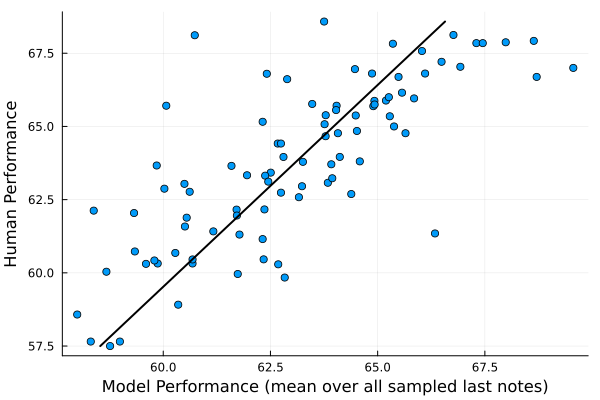

R value = 0.7682783505731615, R-squared value = 0.5902516239594178, p = 9.781734833194104e-19


In [24]:
r_value = cor(human_means, model_means)
ctest = CorrelationTest(human_means, model_means)
p_value = pvalue(ctest)
viz = scatter(model_means, human_means, xlabel="Model Performance (mean over all sampled last notes)", ylabel="Human Performance", legend=false)
df = DataFrame(Y = convert(Array{Float64, 1}, model_means), x = convert(Array{Float64, 1}, human_means))
line = lm(@formula(Y~x), df)
rsq = r2(line)
x_vals = range(minimum(df.x), maximum(df.x), length=100)
y_vals = predict(line, DataFrame(x=x_vals))

display(plot!(viz, y_vals, x_vals, linewidth=2, linecolor = :black))
println("R value = $r_value, R-squared value = $rsq, p = $p_value")

In [25]:
ctest

Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.768278
    95% confidence interval: (0.6674, 0.8415)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-18

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     11.259
    degrees of freedom:              88


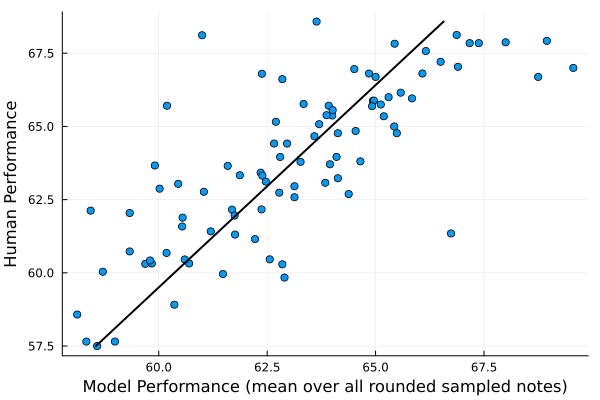

R value = 0.7671223404439818, R-squared value = 0.5884766852082524, p = 1.1847945726999138e-18


In [26]:
r_value = cor(human_means, rounded_model_means)
ctest = CorrelationTest(human_means, rounded_model_means)
p_value = pvalue(ctest)
viz = scatter(rounded_model_means, human_means, xlabel="Model Performance (mean over all rounded sampled notes)", ylabel="Human Performance", legend=false)
df = DataFrame(Y = convert(Array{Float64, 1}, rounded_model_means), x = convert(Array{Float64, 1}, human_means))
line = lm(@formula(Y~x), df)
rsq = r2(line)
x_vals = range(minimum(df.x), maximum(df.x), length=100)
y_vals = predict(line, DataFrame(x=x_vals))

display(plot!(viz, y_vals, x_vals, linewidth=2, linecolor = :black))
println("R value = $r_value, R-squared value = $rsq, p = $p_value")

In [27]:
ctest

Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.767122
    95% confidence interval: (0.6658, 0.8407)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-17

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     11.2178
    degrees of freedom:              88


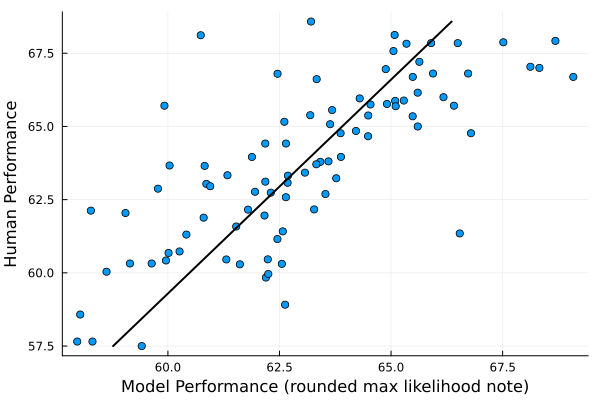

R value = 0.7366126407239864, R-squared value = 0.5425981824743644, p = 1.2892996950639426e-16


In [28]:
r_value = cor(human_means, max_likelihood_notes)
ctest = CorrelationTest(human_means, max_likelihood_notes)
p_value = pvalue(ctest)
viz = scatter(max_likelihood_notes, human_means, xlabel="Model Performance (rounded max likelihood note)", ylabel="Human Performance", legend=false)
df = DataFrame(Y = convert(Array{Float64, 1}, max_likelihood_notes), x = convert(Array{Float64, 1}, human_means))
line = lm(@formula(Y~x), df)
rsq = r2(line)
x_vals = range(minimum(df.x), maximum(df.x), length=100)
y_vals = predict(line, DataFrame(x=x_vals))

display(plot!(viz, y_vals, x_vals, linewidth=2, linecolor = :black))
println("R value = $r_value, R-squared value = $rsq, p = $p_value")

In [29]:
ctest

Test for nonzero correlation
----------------------------
Population details:
    parameter of interest:   Correlation
    value under h_0:         0.0
    point estimate:          0.736613
    95% confidence interval: (0.6248, 0.8188)

Test summary:
    outcome with 95% confidence: reject h_0
    two-sided p-value:           <1e-15

Details:
    number of observations:          90
    number of conditional variables: 0
    t-statistic:                     10.2172
    degrees of freedom:              88


### **Visualize All Melodies**

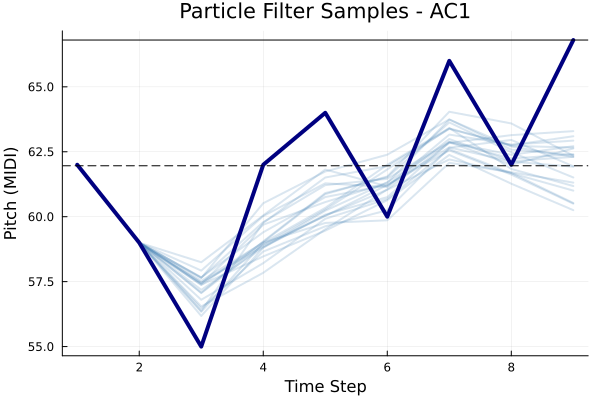

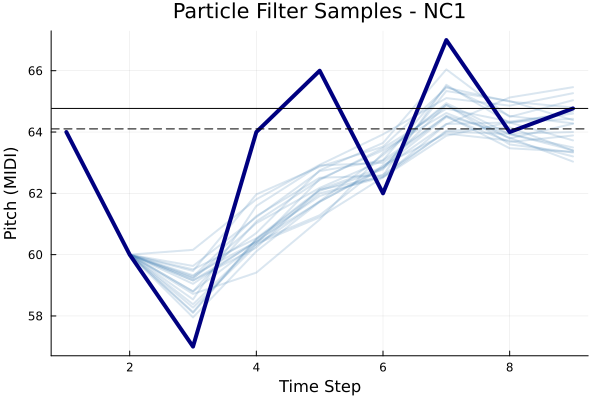

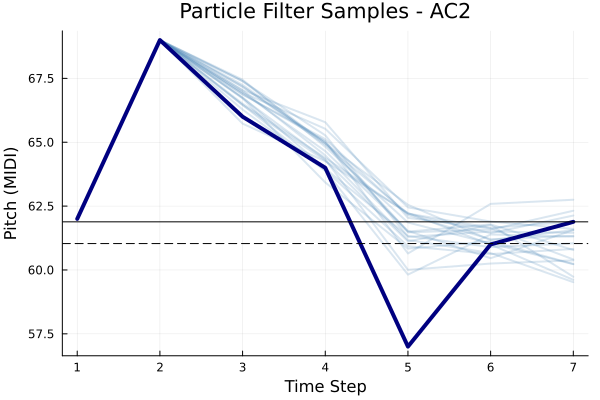

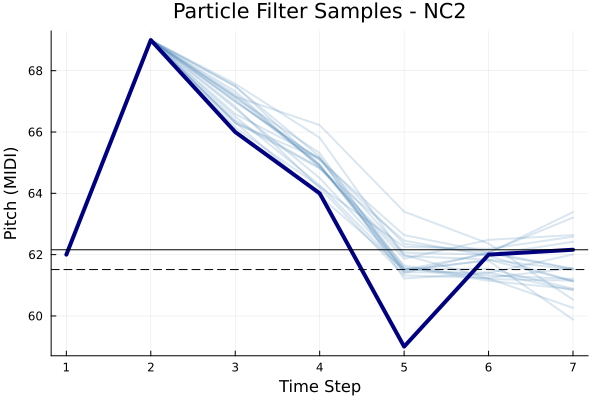

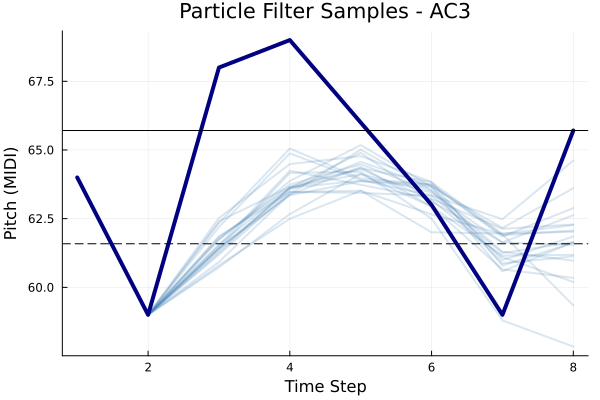

...

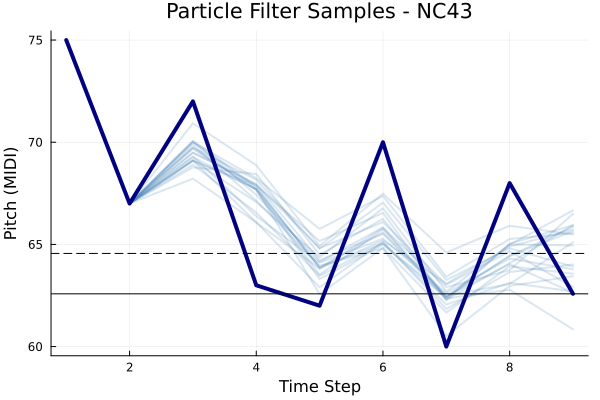

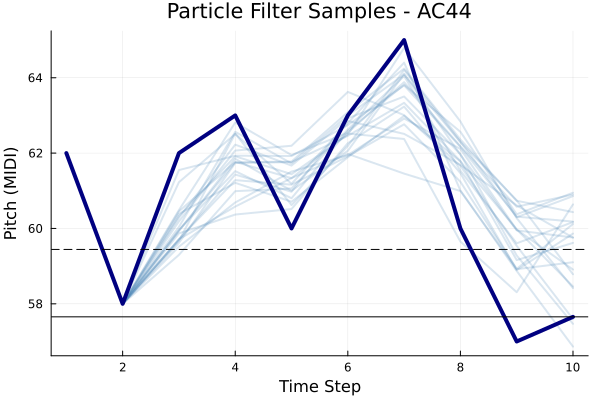

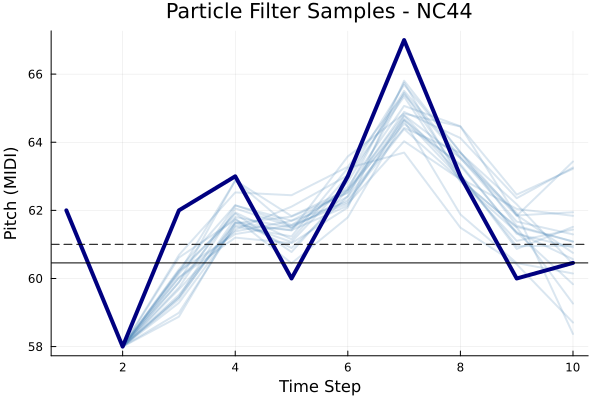

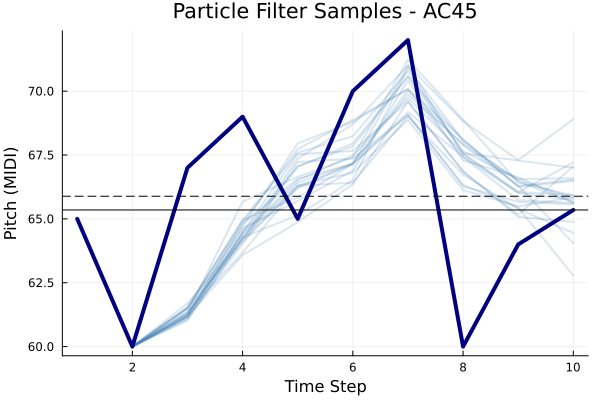

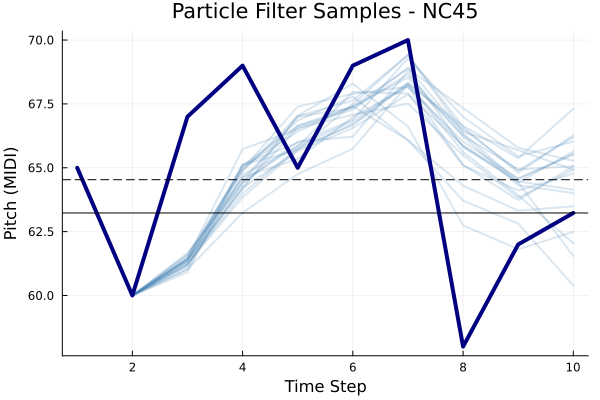

In [30]:
num_melodies = length(melodies)

num_melodies = length(melodies)

for idx in 1:num_melodies
    observed_notes   = melodies[idx]
    observed_rhythms = rhythms[idx]
    obs_notes = [Note(n, p) for (n, p) in zip(observed_notes, observed_rhythms)]
    key              = melody_keys[idx]

    obs_df = make_observations(observed_notes, observed_rhythms, key)

    pf_traces = vcat([
        particle_filter(100, 1, key, obs_df)
        for _ in 1:20
    ]...)

    final_note = Note(human_means[idx], observed_rhythms[end])
    obs_notes_complete = [obs_notes ; final_note]

    plt = visualize_samples(pf_traces, obs_notes_complete, stemIDs[idx])
    savefig(plt, "exports/pf_exports/$(stemIDs[idx])_trace.png")
end
;